#HW1 - Data Exploration and Preparation

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Loading the dataset

In [10]:

train_df_prep = pd.read_csv("train_df_prepared.csv")
test_df_prep = pd.read_csv('test_df_prepared.csv')

In [11]:
train_df_prep.shape

(1000, 26)

In [12]:

train_df_prep = train_df_prep.drop(train_df_prep.columns[0], axis=1)
test_df_prep = test_df_prep.drop(test_df_prep.columns[0], axis=1)
test_df_prep.shape



(250, 25)

In [13]:
train_df_prep.shape


(1000, 25)

In [14]:
from sklearn.neighbors import KNeighborsClassifier
from visualize_clf import visualize_clf

C:\Users\shere\PycharmProjects\pythonProject\.venv\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


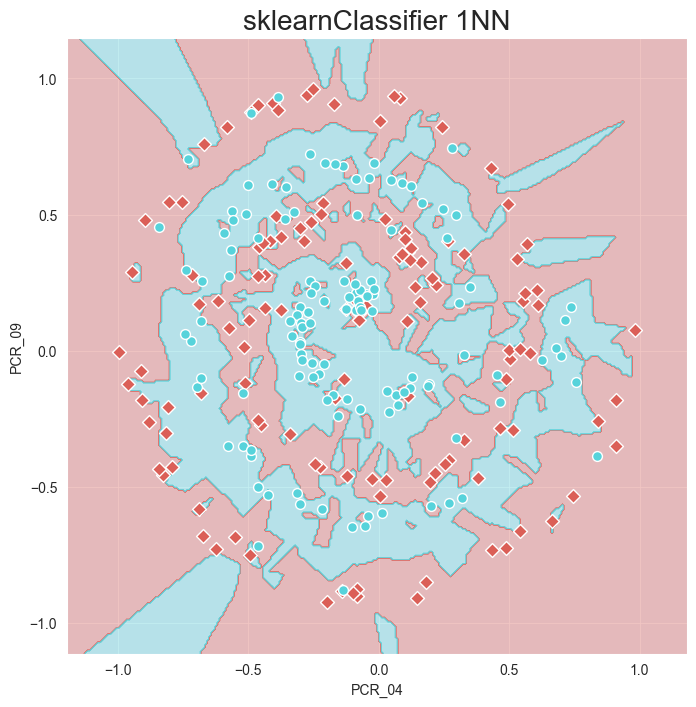

Testing score is: 75.6%


In [15]:
#Q1
from sklearn.metrics import accuracy_score

temp = train_df_prep[['PCR_04', 'PCR_09']]

_1NN = KNeighborsClassifier(n_neighbors=1)

_1NN.fit(temp, train_df_prep['spread'])

visualize_clf(_1NN, test_df_prep[['PCR_04', 'PCR_09']],test_df_prep['spread'], title='sklearnClassifier 1NN', xlabel='PCR_04', ylabel='PCR_09')

preds = _1NN.predict(test_df_prep[['PCR_04', 'PCR_09']])
# Output Scores and Graph
test_score = accuracy_score(test_df_prep['spread'], preds)

print('Testing score is: ' + str(test_score * 100) + '%')


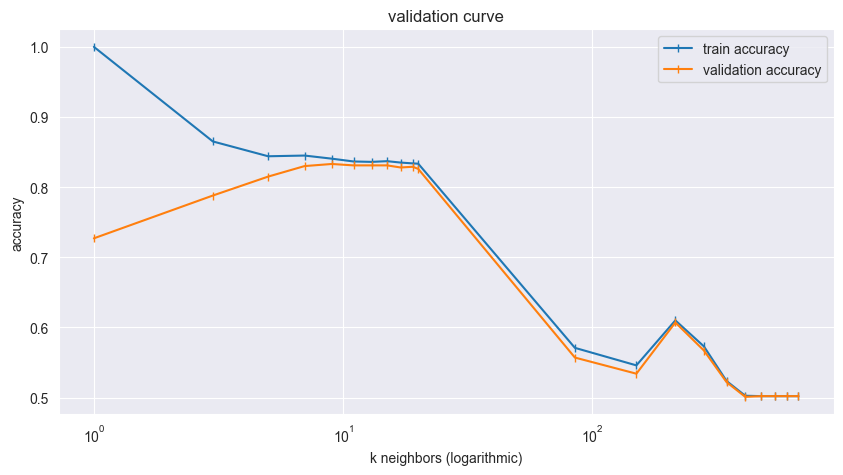

Average train accuracy score: 0.7019183673469389
Average test accuracy score: 0.6792857142857144
[np.float64(0.727), np.float64(0.788), np.float64(0.8150000000000001), np.float64(0.8300000000000001), np.float64(0.8330000000000001), np.float64(0.8310000000000001), np.float64(0.8310000000000001), np.float64(0.8310000000000001), np.float64(0.8280000000000001), np.float64(0.8290000000000001), np.float64(0.8260000000000001), np.float64(0.557), np.float64(0.534), np.float64(0.607), np.float64(0.5670000000000001), np.float64(0.522), np.float64(0.501), np.float64(0.502), np.float64(0.502), np.float64(0.502), np.float64(0.502)]
[1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 20, 85, 150, 215, 280, 345, 410, 475, 540, 605, 670]


In [16]:

#Q2
from sklearn.model_selection import cross_validate

k_range = list(range(1, 20, 2)) + list(range(20, 695, 65))

train_means = []
test_means = []

for k in k_range:
    knn = KNeighborsClassifier(n_neighbors=k)
    res = cross_validate(knn, temp, train_df_prep['spread'], cv=8, return_train_score=True)
    train_means.append(res['train_score'].mean())
    test_means.append(res['test_score'].mean())
    
    
plt.figure(figsize=[10,5])
plt.semilogx(k_range, train_means, label="train accuracy", marker='|')
plt.semilogx(k_range, test_means, label="validation accuracy", marker='|')
plt.xlabel("k neighbors (logarithmic)")
plt.ylabel("accuracy")
plt.title("validation curve")
plt.grid(True)
plt.legend()
plt.show()

average_train_score = np.mean(train_means)
average_test_score = np.mean(test_means)
print("Average train accuracy score:", average_train_score)
print("Average test accuracy score:", average_test_score)

print(test_means)
print(k_range)




Testing score is: 86.0%


C:\Users\shere\PycharmProjects\pythonProject\.venv\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


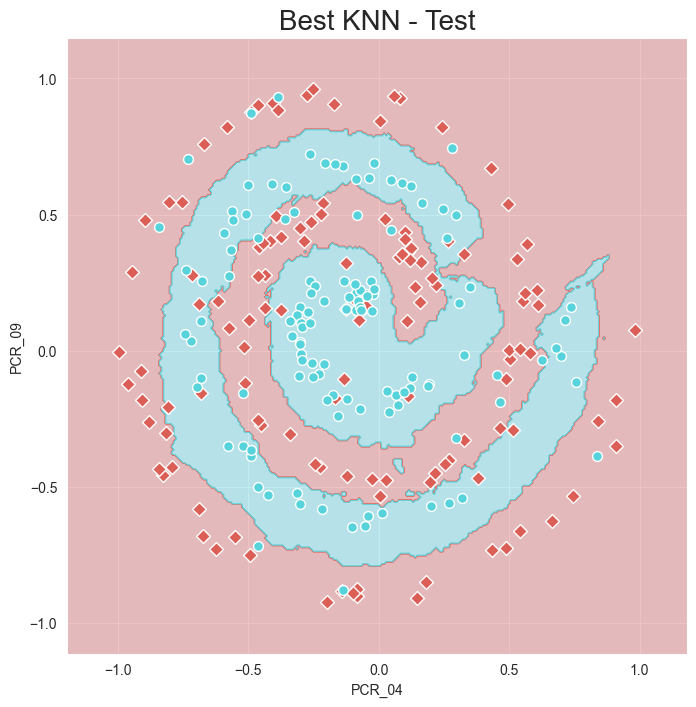

In [17]:
from sklearn.metrics import accuracy_score

#Q3

best_k = 9

best_knn = KNeighborsClassifier(n_neighbors=best_k)
best_knn.fit(temp, train_df_prep['spread'])

# Making our predictions
preds = best_knn.predict(test_df_prep[['PCR_04', 'PCR_09']])
# Output Scores and Graph
test_score = accuracy_score(test_df_prep['spread'], preds)

print('Testing score is: ' + str(test_score * 100) + '%')

visualize_clf(best_knn,test_df_prep[['PCR_04', 'PCR_09']],test_df_prep['spread'], title='Best KNN - Test', xlabel='PCR_04', ylabel='PCR_09')




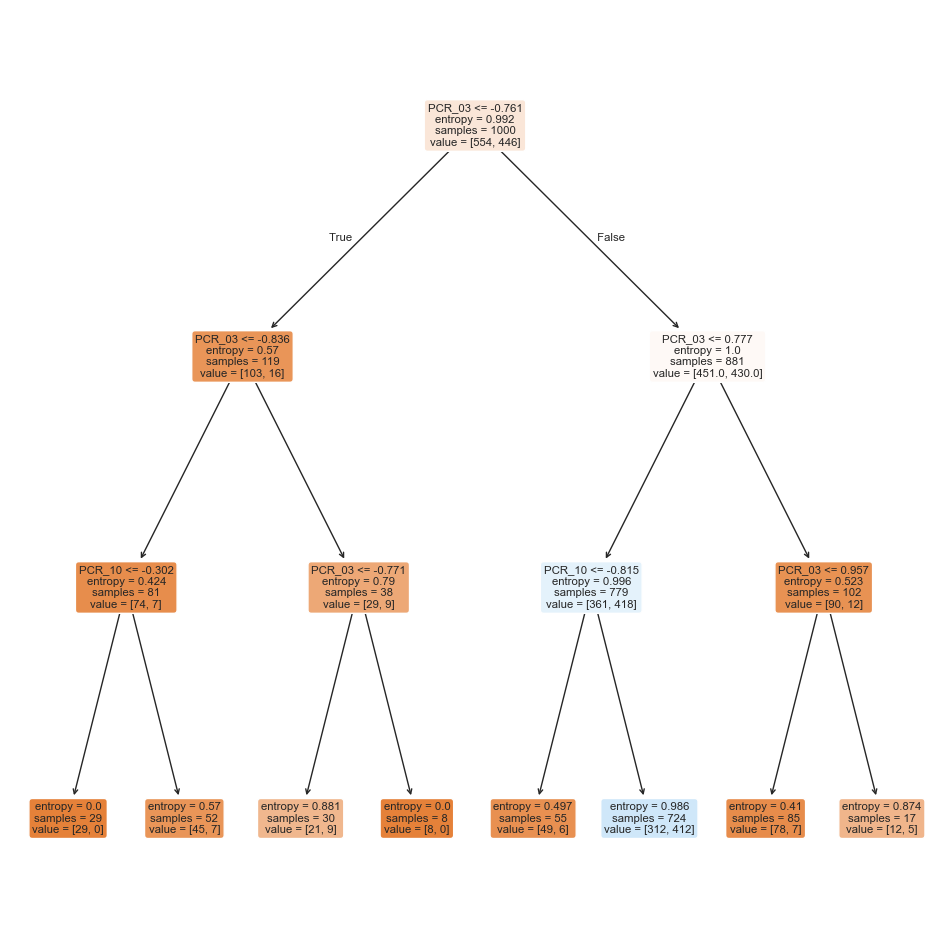

Training score is: 65.4%


In [18]:
#Q5
from sklearn.tree import DecisionTreeClassifier, plot_tree


DT_clf = DecisionTreeClassifier(max_depth=3, criterion='entropy')
DT_clf.fit(train_df_prep[['PCR_03', 'PCR_10']], train_df_prep['risk'])
plt.figure(figsize=(12, 12), dpi=100)
plot_tree(DT_clf, filled=True, rounded=True, feature_names=['PCR_03', 'PCR_10'])
plt.show()


DT_pred = DT_clf.predict(train_df_prep[['PCR_03', 'PCR_10']])
# Output Scores and Graph
train_score = accuracy_score(train_df_prep['risk'], DT_pred)

print('Training score is: ' + str(train_score * 100) + '%')




C:\Users\shere\PycharmProjects\pythonProject\.venv\Lib\site-packages\numpy\ma\core.py:2846: RuntimeWarning: invalid value encountered in cast
  _data = np.array(data, dtype=dtype, copy=copy,


{'max_depth': 13, 'min_samples_leaf': 11}
0.712


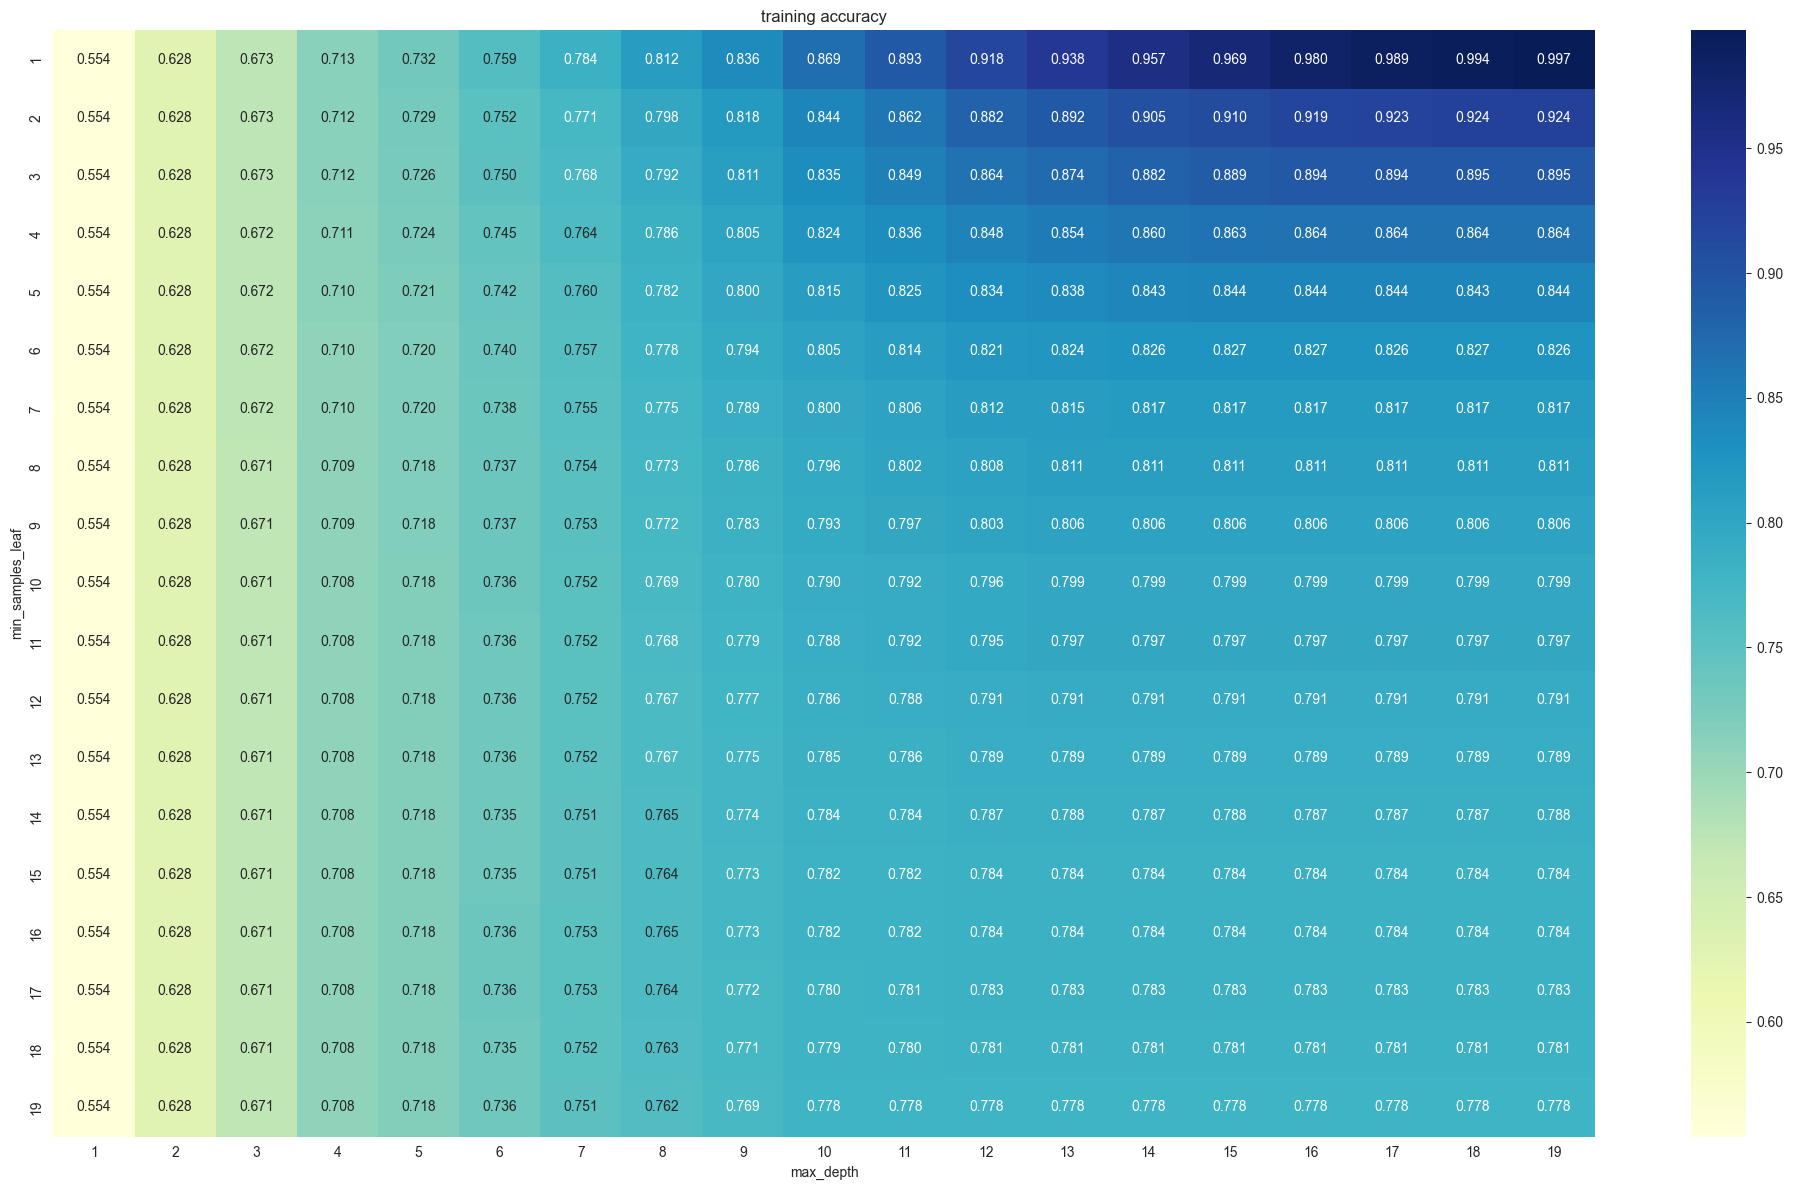

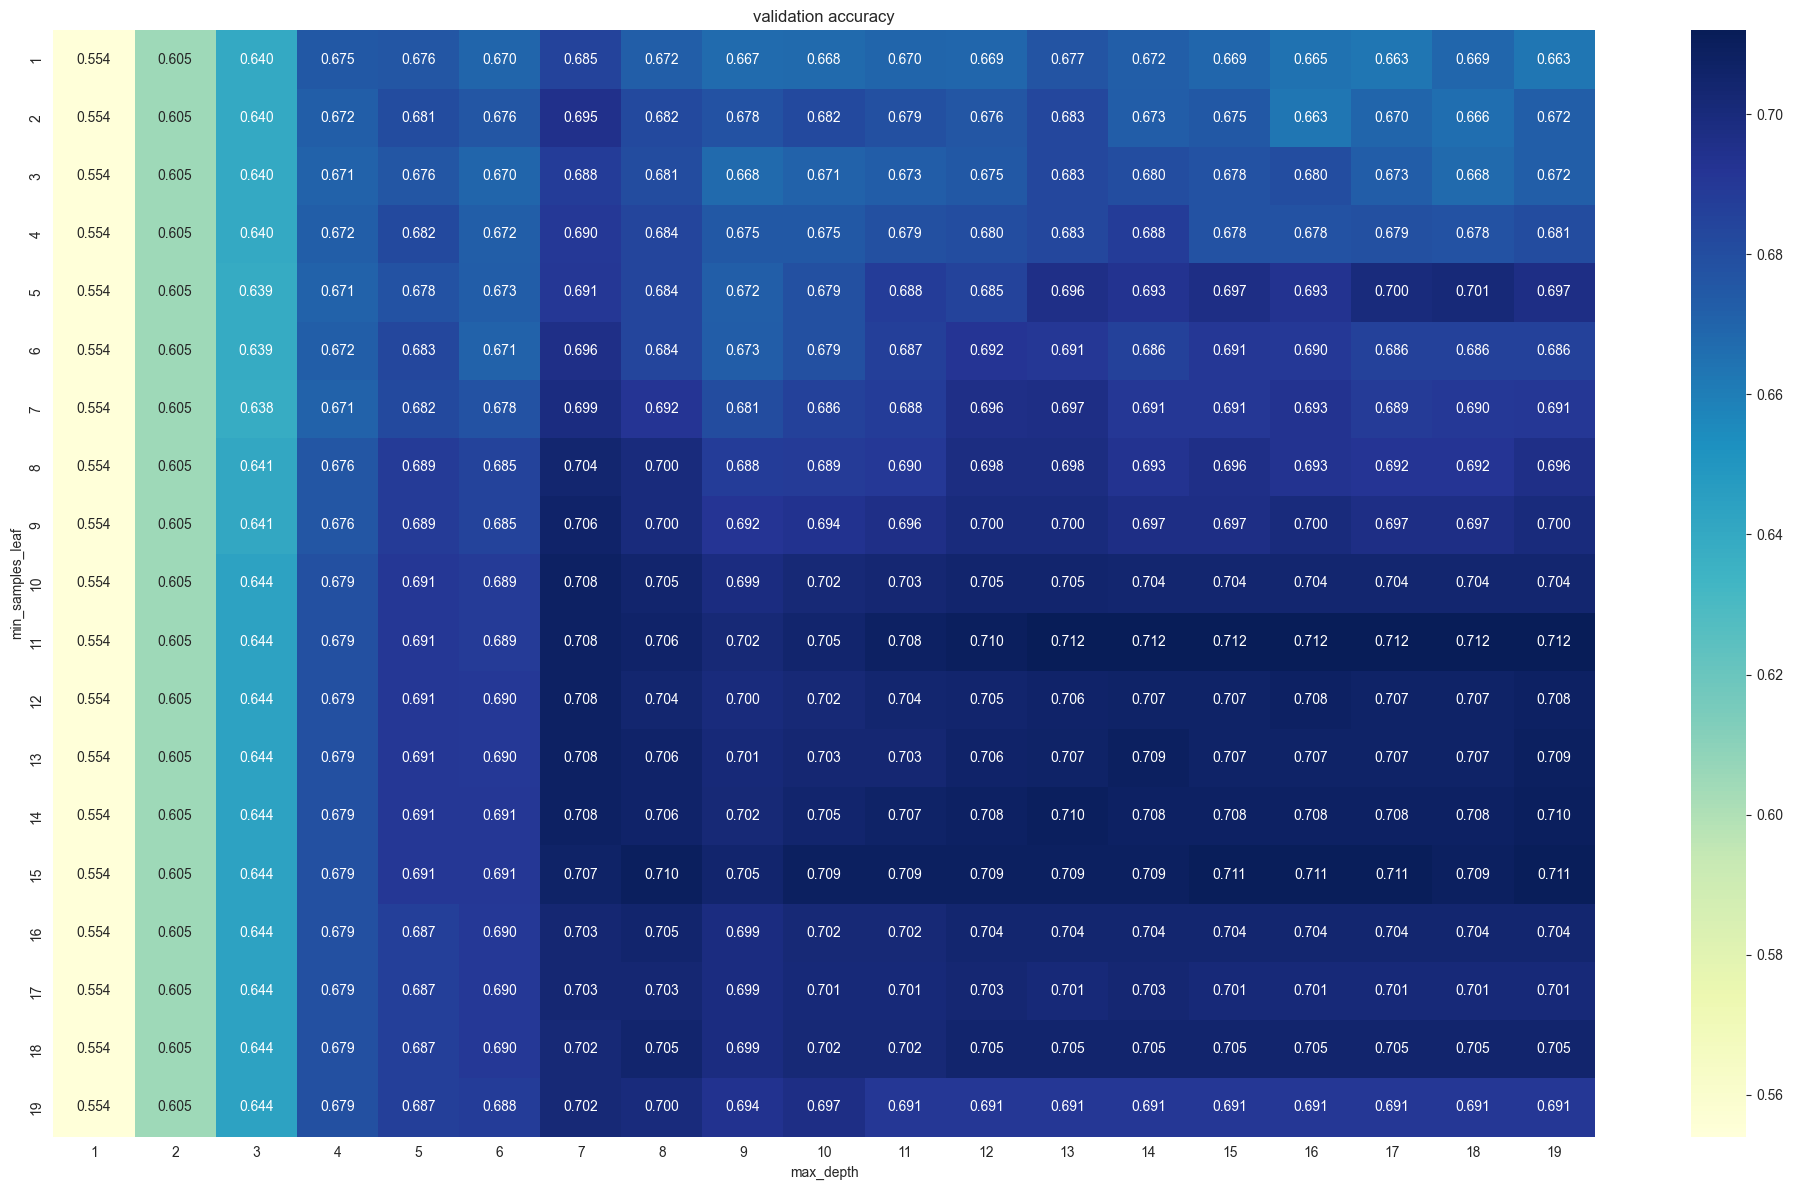

In [19]:
from sklearn.model_selection import GridSearchCV

#Q6

ranges_grid = [ { 'min_samples_leaf': range(1, 20, 1), 'max_depth': range(1, 20, 1) } ]


general_dt = DecisionTreeClassifier()
res = GridSearchCV(estimator=general_dt, param_grid=ranges_grid, cv=5, return_train_score=True)
res.fit(train_df_prep[['PCR_03', 'PCR_10']], train_df_prep['risk'])
print(res.best_params_)
print(res.best_score_)

mean_train_pivot = pd.DataFrame(res.cv_results_).pivot(index='param_min_samples_leaf', columns='param_max_depth', values='mean_train_score')
mean_test_pivot = pd.DataFrame(res.cv_results_).pivot(index='param_min_samples_leaf', columns='param_max_depth', values='mean_test_score')



plt.figure(figsize=(20, 12))
sns.heatmap(mean_train_pivot, annot=True, fmt=".3f", cmap="YlGnBu")
plt.title("training accuracy")
plt.xlabel("max_depth")
plt.ylabel("min_samples_leaf")
plt.tight_layout()
plt.show()


plt.figure(figsize=(20, 12))
sns.heatmap(mean_test_pivot, annot=True, fmt=".3f", cmap="YlGnBu")
plt.title("validation accuracy")
plt.xlabel("max_depth")
plt.ylabel("min_samples_leaf")
plt.tight_layout()
plt.show()



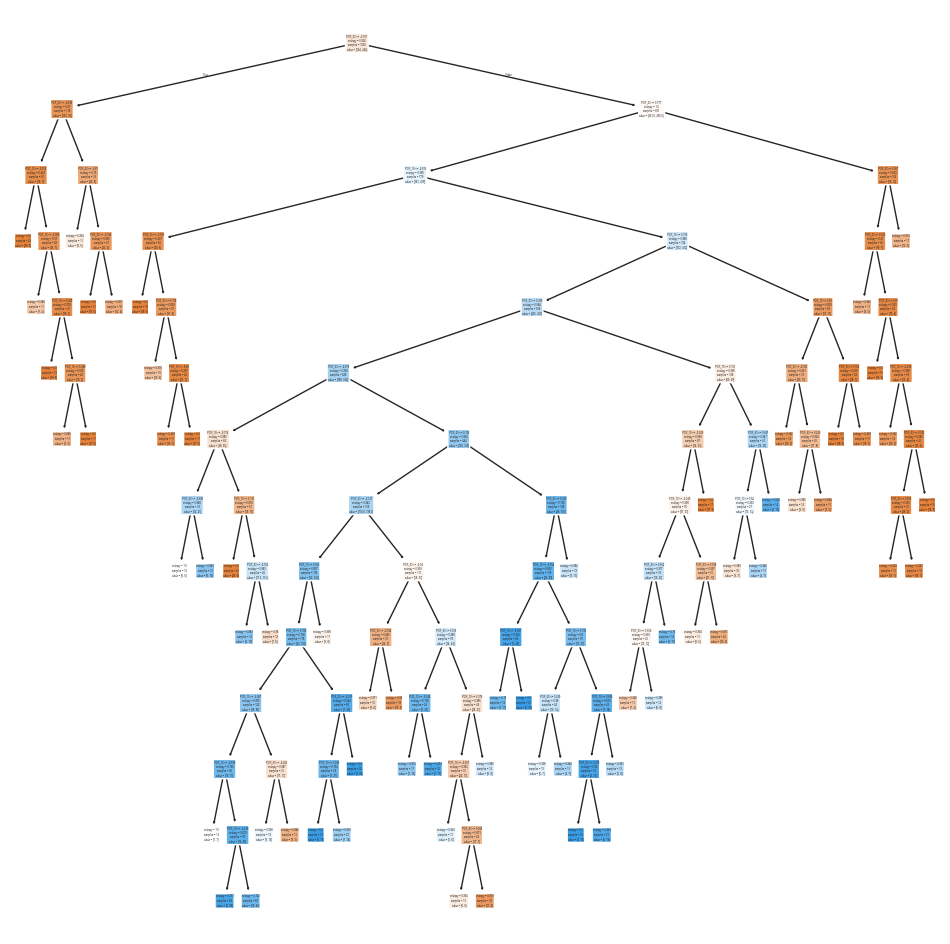

Testing score is: 74.0%


In [20]:
#Q8

optimal_max_depth = 13
optimal_min_samples_leaf = 11

DT_clf = DecisionTreeClassifier(max_depth=optimal_max_depth, min_samples_leaf=optimal_min_samples_leaf ,criterion='entropy')
DT_clf.fit(train_df_prep[['PCR_03', 'PCR_10']], train_df_prep['risk'])
plt.figure(figsize=(12, 12), dpi=100)
plot_tree(DT_clf, filled=True, rounded=True, feature_names=['PCR_03', 'PCR_10'])
plt.show()

#predict on test
optimal_pred = DT_clf.predict(test_df_prep[['PCR_03', 'PCR_10']])

# Output Scores and Graph

test_score = accuracy_score(test_df_prep['risk'], optimal_pred)
print('Testing score is: ' + str(test_score * 100) + '%')





In [21]:

from sklearn.base import BaseEstimator, ClassifierMixin
import numpy as np

class SoftSVM(BaseEstimator, ClassifierMixin):
    """
    Custom C-Support Vector Classification.
    """
    def __init__(self, C: float, lr: float = 1e-5, batch_size = 32):
        """
        Initialize an instance of this class.
        ** Do not edit this method **

        :param C: inverse strength of regularization. Must be strictly positive.
        :param lr: the SGD learning rate (step size)
        """
        self.C = C
        self.lr = lr
        self.batch_size = batch_size
        self.w = None
        self.b = 0.0

    # Initialize a random weight vector
    def init_solution(self, n_features: int):
        """
        Randomize an initial solution (weight vector)
        ** Do not edit this method **

        :param n_features:
        """
        self.w = np.random.randn(n_features)
        self.b = 0.0

    @staticmethod
    def loss(w, b: float, C: float, X, y):
        """
        Compute the SVM objective loss.

        :param w: weight vector for linear classification; array of shape (n_features,)
        :param b: bias scalar for linear classification
        :param C: inverse strength of regularization. Must be strictly positive.
        :param X: samples for loss computation; array of shape (n_samples, n_features)
        :param y: targets for loss computation; array of shape (n_samples,)
        :return: the Soft SVM objective loss (float scalar)
        """
        margins = (X.dot(w) + b).reshape(-1, 1)
        hinge_inputs = np.multiply(margins, y.reshape(-1, 1))

        norm = np.linalg.norm(w)

        # TODO: complete the loss calculation: DONE
        loss = norm**2 + C * np.sum(np.maximum(0,1-hinge_inputs))

        return loss

    @staticmethod
    def subgradient(w, b: float, C: float, X, y):
        """
        Compute the (analytical) SVM objective sub-gradient.

        :param w: weight vector for linear classification; array of shape (n_features,)
        :param b: bias scalar for linear classification
        :param C: inverse strength of regularization. Must be strictly positive.
        :param X: samples for loss computation; array of shape (n_samples, n_features)
        :param y: targets for loss computation; array of shape (n_samples,)
        :return: a tuple with (the gradient of the weights, the gradient of the bias)
        """
        # TODO: calculate the analytical sub-gradient of soft-SVM w.r.t w and b DONE
        margins = (X.dot(w) + b).reshape(-1, 1)
        hinge_inputs = np.multiply(margins, y.reshape(-1, 1))
        
        f_with_input = -((np.sign(-hinge_inputs + 1)).astype(int))
        f_with_input[f_with_input == 1.0] = 0

        
        f_with_input_mult_y = f_with_input * y.reshape(-1, 1)


        full_sum = np.sum(np.multiply(f_with_input_mult_y, X), axis=0)
        
        
        
        
        g_w = np.multiply(w,2) + C* full_sum
        
        g_b = C * np.sum(f_with_input_mult_y)

        return g_w, g_b

    def fit_with_logs(self, X, y, max_iter: int = 2000, keep_losses: bool = True):
        """
        Fit the model according to the given training data.

        :param X: training samples; array of shape (n_samples, n_features)
        :param y: training targets (+1 and -1); array of shape (n_samples,)
        :param max_iter: number of SGD iterations
        :param keep_losses:
        :return: the training losses and accuracies during training
        """
        # Initialize learned parameters
        self.init_solution(X.shape[1])

        losses = []
        accuracies = []

        if keep_losses:
            losses.append(self.loss(self.w, self.b, self.C, X, y))
            accuracies.append(self.score(X, y))

        permutation = np.random.permutation(len(y))
        X = X[permutation, :]
        y = y[permutation]
        
        # Iterate over batches
        for iter in range(0, max_iter):
            start_idx = (iter * self.batch_size) % X.shape[0]
            end_idx = min(X.shape[0], start_idx + self.batch_size)
            batch_X = X[start_idx:end_idx, :]
            batch_y = y[start_idx:end_idx]

            # TODO: Compute the (sub)gradient of the current *batch*
            g_w, g_b = self.subgradient(self.w, self.b, self.C, batch_X, batch_y)

            # Perform a (sub)gradient step
            # TODO: update the learned parameters correctly
            self.w = self.w - self.lr * g_w
            self.b = self.b - self.lr * g_b
            
            
            if keep_losses:
                losses.append(self.loss(self.w, self.b, self.C, X, y))
                accuracies.append(self.score(X, y))

        return losses, accuracies

    def fit(self, X, y, max_iter: int = 2000):
        """
        Fit the model according to the given training data.
        ** Do not edit this method **

        :param X: training samples; array of shape (n_samples, n_features)
        :param y: training targets (+1 and -1); array of shape (n_samples,)
        :param max_iter: number of SGD iterations
        """
        self.fit_with_logs(X, y, max_iter=max_iter, keep_losses=False)

        return self

    def predict(self, X):
        """
        Perform classification on samples in X.

        :param X: samples for prediction; array of shape (n_samples, n_features)
        :return: Predicted class labels for samples in X; array of shape (n_samples,)
                 NOTE: the labels must be either +1 or -1
        """
        # TODO: compute the predicted labels (+1 or -1)
        result = np.sign(X.dot(self.w) + self.b)
        result[result == 0] = 1
        y_pred = result

        return y_pred


In [22]:
def numerical_subgradient(w, b, C, X, y, delta=1e-4):
    w_ = w.copy()
    g_w = np.zeros_like(w_)
    orig_objective = SoftSVM.loss(w_, b, C, X, y)
    for i in range(g_w.shape[0]):
        w_[i] += delta
        perturbed_objective = SoftSVM.loss(w_, b, C, X, y)
        w_[i] -= delta
        g_w[i] = (perturbed_objective - orig_objective) / delta

    g_b = (SoftSVM.loss(w_, b + delta, C, X, y) - orig_objective) / delta
    return g_w, g_b



def compare_gradients(X, y, deltas, C=1, REPEATS=100, figsize=(10, 6)):
    residual_means = []

    for delta in deltas:
        residuals = []

        for _ in range(REPEATS):
            # Randomize vectors in which the gradient is computed
            w = np.random.randn(X.shape[1])
            b = np.random.randn(1)

            # Compute the two types of gradients
            analytic_grad = SoftSVM.subgradient(w, b, C, X, y)[0]
            numeric_grad = numerical_subgradient(w, b, C, X, y, delta=delta)[0]

            residual = np.linalg.norm(numeric_grad - analytic_grad)
            residuals.append(residual)

        residual_means.append(np.mean(residuals))

    plt.figure(figsize=figsize)
    plt.title('Residuals of analytical and numerical gradients', fontsize=22)
    plt.plot(deltas, residual_means, linewidth=3)      
    plt.yscale('log')
    plt.xscale('log')
    plt.xlabel('$\delta$', fontsize=18)
    plt.ylabel(r'$\left\Vert \nabla_{w}p_{C}\left(w,b\right) - u_{\delta} \left(w,b\right)\right\Vert$', fontsize=18)

    plt.grid(alpha=0.5)
    plt.show()


<>:41: SyntaxWarning: invalid escape sequence '\d'
<>:41: SyntaxWarning: invalid escape sequence '\d'
C:\Users\shere\AppData\Local\Temp\ipykernel_22204\1918640999.py:41: SyntaxWarning: invalid escape sequence '\d'
  plt.xlabel('$\delta$', fontsize=18)


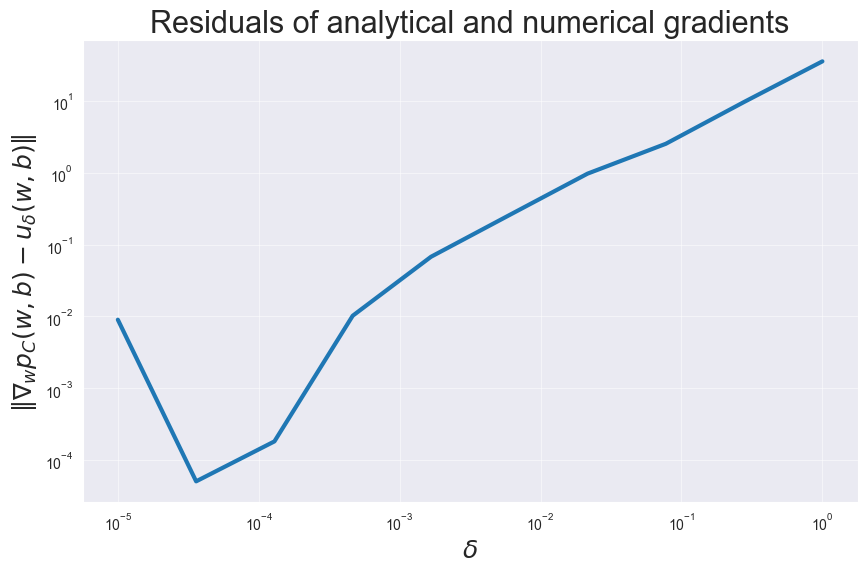

In [23]:
#Q9

compare_gradients(X=train_df_prep[['PCR_04', 'PCR_09']].values, y=train_df_prep['spread'].values, deltas=np.logspace(-5, 0, 10))

CURRENT LR: 1e-11


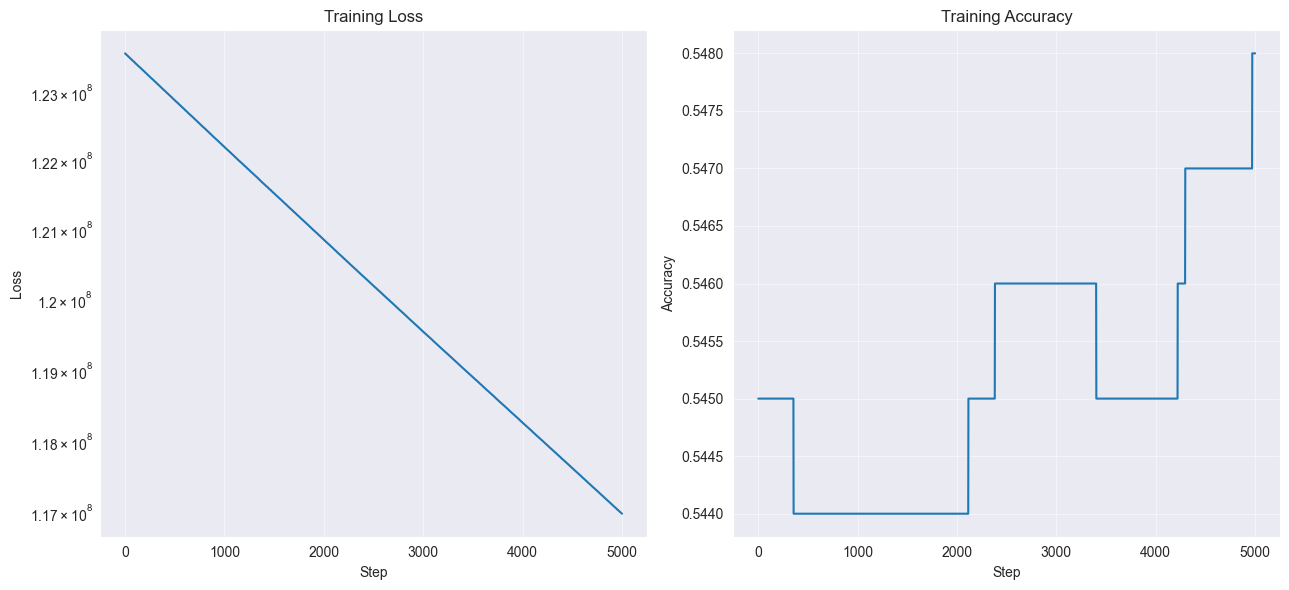

CURRENT LR: 1e-09


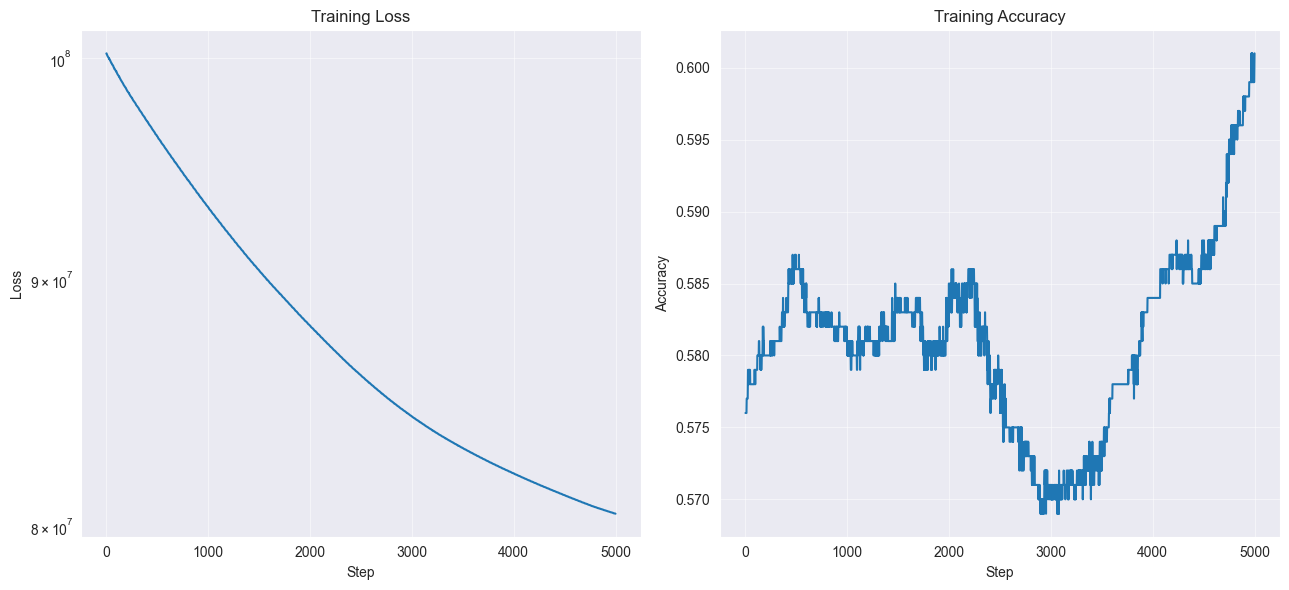

CURRENT LR: 1e-07


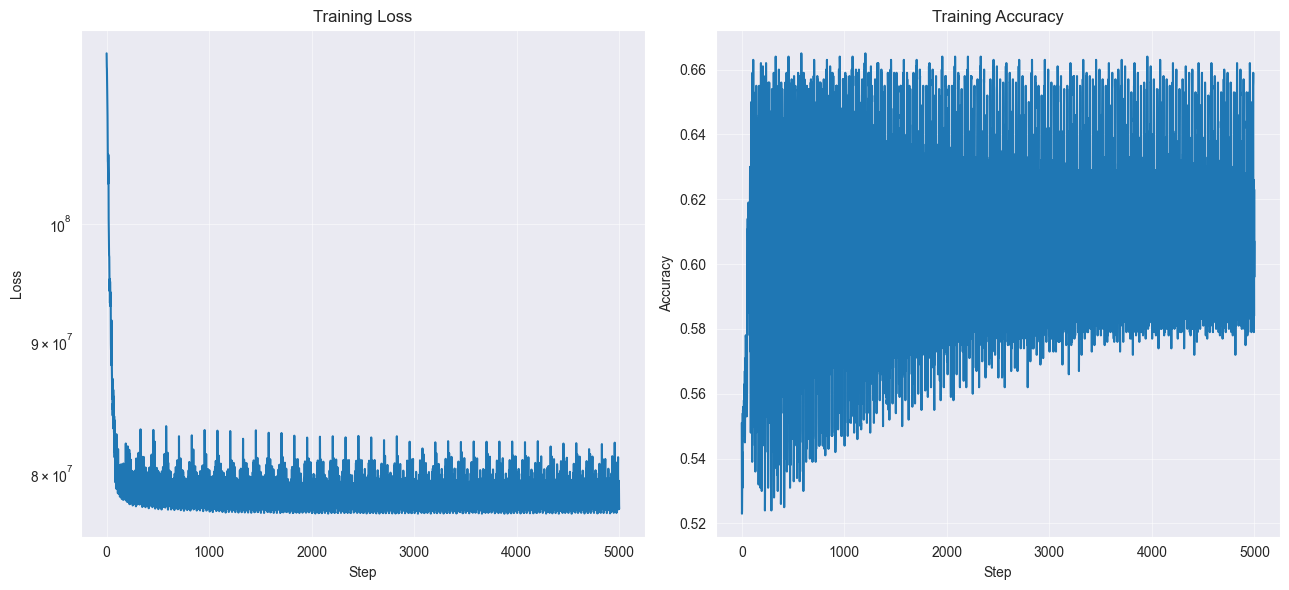

CURRENT LR: 1e-05


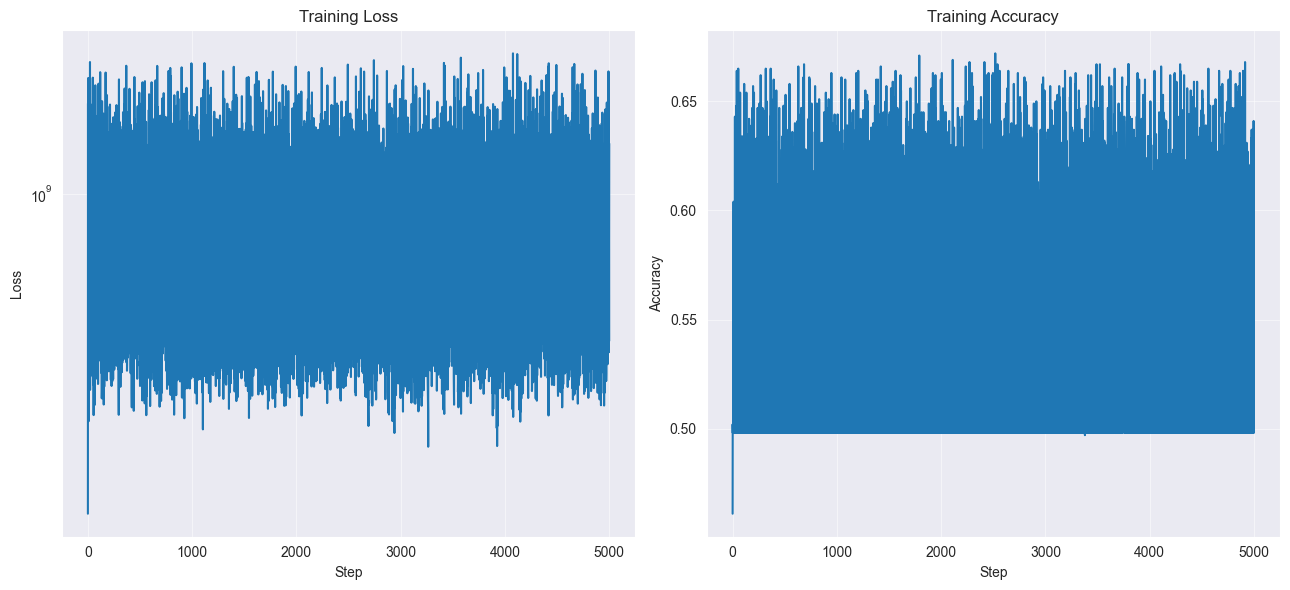

CURRENT LR: 0.001


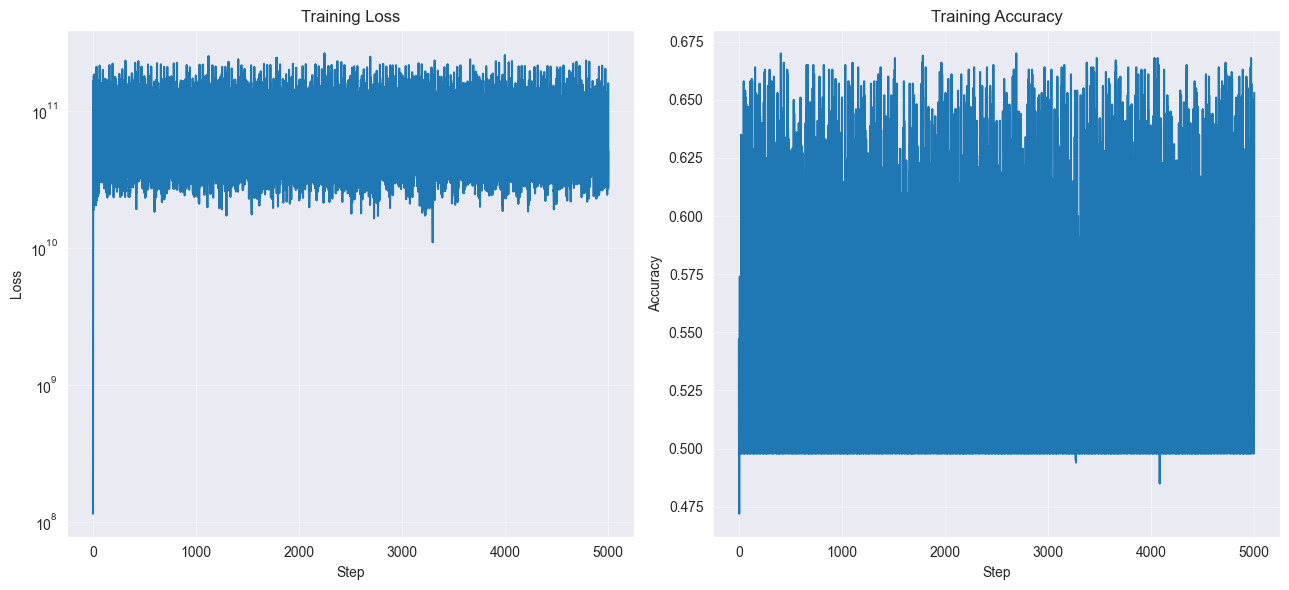

In [24]:
from sklearn.preprocessing import PolynomialFeatures, MinMaxScaler

# Task Before Q11

C=1e5
for lr in np.logspace(-11, -3, 5):
    print("CURRENT LR:", lr)
    clf = SoftSVM(C=C, lr=lr)
    X_train_poly = PolynomialFeatures(degree=3,).fit_transform(train_df_prep[['PCR_04', 'PCR_09']].values)
    X_train_poly = MinMaxScaler(feature_range=(-1,1)).fit_transform(X_train_poly)
    losses, accuracies = clf.fit_with_logs(X_train_poly, train_df_prep['spread'].values, max_iter=5000)
    plt.figure(figsize=(13, 6))
    plt.subplot(121), plt.grid(alpha=0.5), plt.title ("Training Loss")
    plt.semilogy(losses), plt.xlabel("Step"), plt.ylabel("Loss")
    plt.subplot(122), plt.grid(alpha=0.5), plt.title ("Training Accuracy")
    plt.plot(accuracies), plt.xlabel("Step"), plt.ylabel("Accuracy")
    plt.tight_layout()
    plt.show()

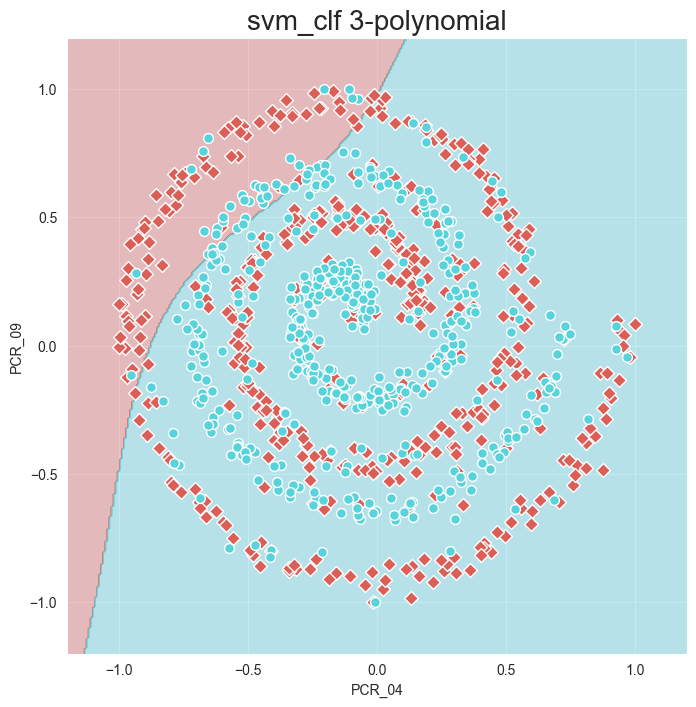

Testing score is: 74.0%
Training score is: 53.5%


C:\Users\shere\PycharmProjects\pythonProject\.venv\Lib\site-packages\sklearn\base.py:486: UserWarning: X has feature names, but PolynomialFeatures was fitted without feature names
  warnings.warn(
C:\Users\shere\PycharmProjects\pythonProject\.venv\Lib\site-packages\sklearn\base.py:486: UserWarning: X has feature names, but PolynomialFeatures was fitted without feature names
  warnings.warn(


In [25]:
#Q12

from sklearn.preprocessing import MinMaxScaler
from sklearn.pipeline import Pipeline


svm_clf = Pipeline([('feature_mapping', PolynomialFeatures(degree=3,)),
                    ('scaler', MinMaxScaler()),
                    ('SVM', SoftSVM(C=1e5, lr=1e-09))])
svm_clf.fit(train_df_prep[['PCR_04', 'PCR_09']].values, train_df_prep['spread'].values)

visualize_clf(svm_clf,X=train_df_prep[['PCR_04', 'PCR_09']].values, Y=train_df_prep['spread'].values, title='svm_clf 3-polynomial',xlabel='PCR_04', ylabel='PCR_09')


test_prediction = svm_clf.predict(test_df_prep[['PCR_04', 'PCR_09']])
test_score_3_poly = accuracy_score(test_df_prep['spread'], test_prediction)
print('Testing score is: ' + str(test_score * 100) + '%')


train_prediction = svm_clf.predict(train_df_prep[['PCR_04', 'PCR_09']]) 
train_score = accuracy_score(train_df_prep['spread'], train_prediction)
print('Training score is: ' + str(train_score * 100) + '%')



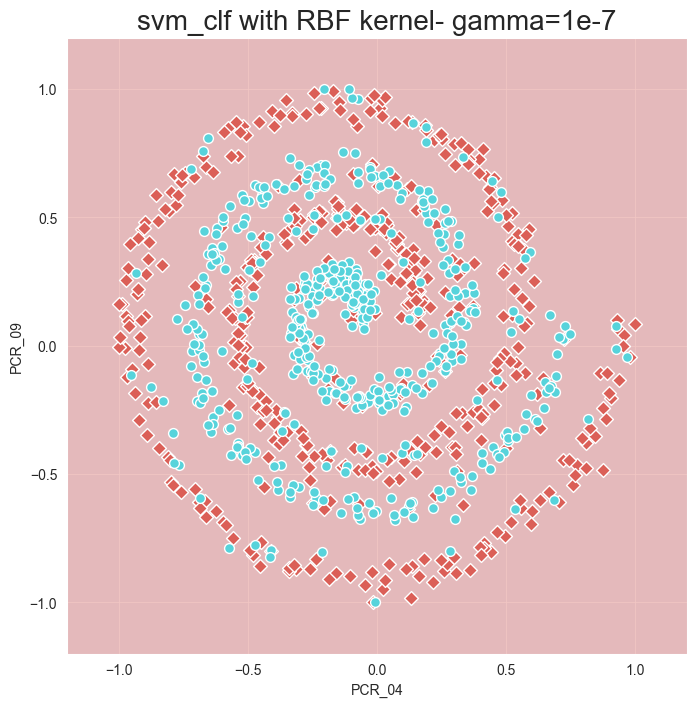

Testing score is: 49.2%
Training score is: 50.2%


C:\Users\shere\PycharmProjects\pythonProject\.venv\Lib\site-packages\sklearn\base.py:486: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(
C:\Users\shere\PycharmProjects\pythonProject\.venv\Lib\site-packages\sklearn\base.py:486: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(


In [32]:
#Q14
from sklearn.svm import SVC
# the SVM model
svm_clf = SVC(kernel='rbf', C=1, gamma=1e-7)

svm_clf.fit(train_df_prep[['PCR_04', 'PCR_09']].values, train_df_prep['spread'].values)

visualize_clf(svm_clf,X=train_df_prep[['PCR_04', 'PCR_09']].values, Y=train_df_prep['spread'].values, title='svm_clf with RBF kernel- gamma=1e-7',xlabel='PCR_04', ylabel='PCR_09')


test_prediction = svm_clf.predict(test_df_prep[['PCR_04', 'PCR_09']])
test_score_rbf_kernel = accuracy_score(test_df_prep['spread'], test_prediction)
print('Testing score is: ' + str(test_score_rbf_kernel * 100) + '%')


train_prediction = svm_clf.predict(train_df_prep[['PCR_04', 'PCR_09']])
train_score_rbf_kernel = accuracy_score(train_df_prep['spread'], train_prediction)
print('Training score is: ' + str(train_score_rbf_kernel  * 100) + '%')

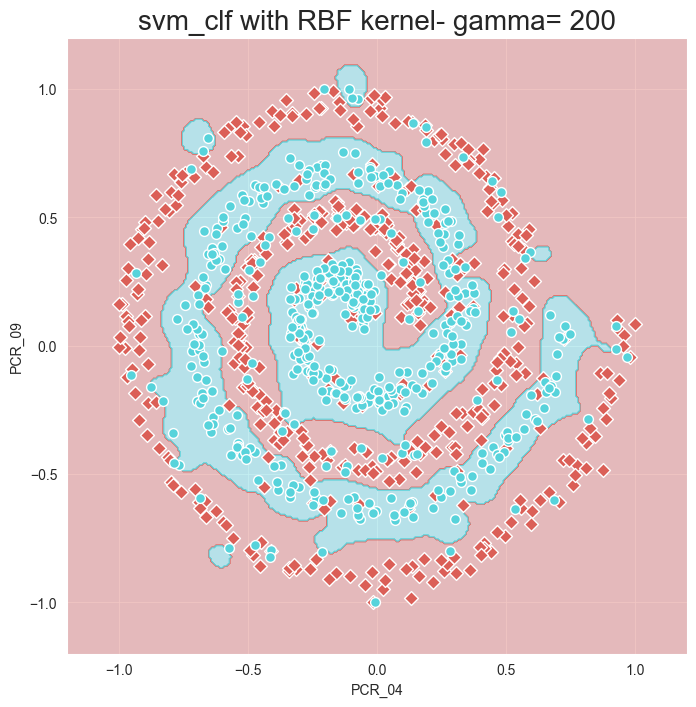

Testing score is: 84.0%
Training score is: 85.5%


C:\Users\shere\PycharmProjects\pythonProject\.venv\Lib\site-packages\sklearn\base.py:486: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(
C:\Users\shere\PycharmProjects\pythonProject\.venv\Lib\site-packages\sklearn\base.py:486: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(


In [33]:
#Q15

# the SVM model
svm_clf = SVC(kernel='rbf', C=1, gamma=200)

svm_clf.fit(train_df_prep[['PCR_04', 'PCR_09']].values, train_df_prep['spread'].values)

visualize_clf(svm_clf,X=train_df_prep[['PCR_04', 'PCR_09']].values, Y=train_df_prep['spread'].values, title='svm_clf with RBF kernel- gamma= 200',xlabel='PCR_04', ylabel='PCR_09')


test_prediction = svm_clf.predict(test_df_prep[['PCR_04', 'PCR_09']])
test_score_rbf_kernel = accuracy_score(test_df_prep['spread'], test_prediction)
print('Testing score is: ' + str(test_score_rbf_kernel * 100) + '%')


train_prediction = svm_clf.predict(train_df_prep[['PCR_04', 'PCR_09']])
train_score_rbf_kernel = accuracy_score(train_df_prep['spread'], train_prediction)
print('Training score is: ' + str(train_score_rbf_kernel  * 100) + '%')


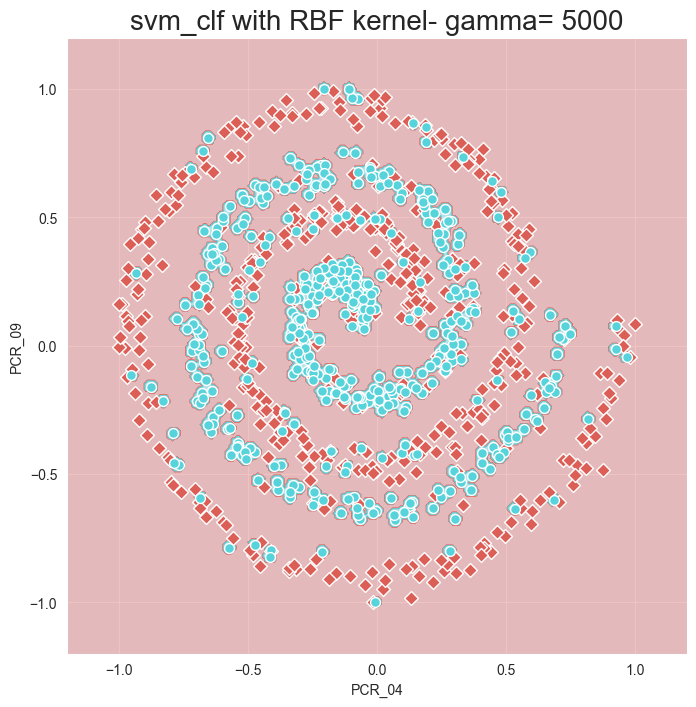

Testing score is: 70.39999999999999%
Training score is: 98.4%


C:\Users\shere\PycharmProjects\pythonProject\.venv\Lib\site-packages\sklearn\base.py:486: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(
C:\Users\shere\PycharmProjects\pythonProject\.venv\Lib\site-packages\sklearn\base.py:486: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(


In [34]:
#Q16
# the SVM model
svm_clf = SVC(kernel='rbf', C=1, gamma=5000)

svm_clf.fit(train_df_prep[['PCR_04', 'PCR_09']].values, train_df_prep['spread'].values)

visualize_clf(svm_clf,X=train_df_prep[['PCR_04', 'PCR_09']].values, Y=train_df_prep['spread'].values, title='svm_clf with RBF kernel- gamma= 5000',xlabel='PCR_04', ylabel='PCR_09')


test_prediction = svm_clf.predict(test_df_prep[['PCR_04', 'PCR_09']])
test_score_rbf_kernel = accuracy_score(test_df_prep['spread'], test_prediction)
print('Testing score is: ' + str(test_score_rbf_kernel * 100) + '%')


train_prediction = svm_clf.predict(train_df_prep[['PCR_04', 'PCR_09']])
train_score_rbf_kernel = accuracy_score(train_df_prep['spread'], train_prediction)
print('Training score is: ' + str(train_score_rbf_kernel  * 100) + '%')
